In [1]:
import ot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import math
import scipy
from scipy.spatial import cKDTree
from scipy import integrate
from scipy import interpolate
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi
from itertools import product
import torch
torch.manual_seed(100000)
import torch.nn as nn
import torch.optim as optim

np.random.seed(100000)  # NEW: keep the noisy data and sampled indices fixed

In [2]:
# settings
start = np.array((0., 1., 1.05))
dt = 0.01
subset_size = 20  # cell number
slope = 0.5  # original weighting parameter (epsilon = 1/slope)
traj_length = int(1e7)
noise_level = 0.5
sample_size = int(500)
epsilon = 1e-4  # original teleportation parameter (not the weighting epsilon)
sampling_time = 1
simulation_t = int(2e4)
steps = 5
N_iters = 10000

# NEW: ablation settings
eps_values = np.linspace(0.5, 40, 10)#[1.0, 1.25, 1.5, 2.0, 2.5]#weighting parameter #2 in manuscript
mesh_shape = (2, 2, 5)  # 20 uniform centers
n_trials = 10
invert_variables = [0]  # Hybrid model; use [0, 1, 2] to learn all derivatives.
ot_max_iter = 1000000

In [3]:
def Lorenz(x):
    x = x.T
    return np.array((10 * (x[1] - x[0]),
                     x[0] * (28 - x[2]) - x[1],
                     x[0] * x[1] - (8/3) * x[2])).T


def Lorenz_vec(x):
    return torch.stack((10 * (x[:, 1] - x[:, 0]),
                        x[:, 0] * (28 - x[:, 2]) - x[:, 1],
                        x[:, 0] * x[:, 1] - (8/3) * x[:, 2]), dim=1)


def traj(length, starts=start, model=Lorenz):
    x = starts
    values = np.zeros((length, len(starts)))
    values[0] = x
    for i in range(length - 1):
        x = x + dt * model(x)
        values[i + 1] = x
    return values


def invariant_measure(matrix):
    N = len(matrix)
    rhs = matrix.new_full((N,), epsilon / N)
    identity = torch.eye(N, dtype=matrix.dtype, device=matrix.device)
    return torch.linalg.solve(identity - (1 - epsilon) * matrix, rhs)


def w(xs):
    dists = torch.cdist(xs, Voronoi_centers)
    if not torch.isfinite(dists).all():
        raise ValueError("Nonfinite states encountered while computing cell weights.")
    weights = torch.relu(1 - slope * dists)
    mass = weights.sum(dim=1, keepdim=True)
    nearest = nn.functional.one_hot(dists.argmin(dim=1), subset_size).to(weights)
    denominator = torch.where(mass > 0, mass, torch.ones_like(mass))
    return torch.where(mass > 0, weights / denominator, nearest)


def Ulam(points, Tpoints):
    with torch.no_grad():
        indices = torch.as_tensor(tree.query(points.detach().cpu().numpy())[1],
                                  dtype=torch.long, device=points.device)
    weights = w(Tpoints).to(torch.float64)
    mat = weights.new_zeros((subset_size, subset_size))
    mat.index_add_(0, indices, weights)
    mass = mat.sum(dim=1, keepdim=True)
    # Unobserved source cells have no estimated outgoing transitions.
    mat = torch.where(mass > 0, mat / mass.clamp_min(1e-12),
                      torch.full_like(mat, 1 / subset_size))
    return mat.T


class W2Loss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, im_net):

        a = np.asarray(im_true_np, dtype=np.float64)
        raw_b = im_net.detach().cpu().numpy().astype(np.float64)
        total_a, total = a.sum(), raw_b.sum()

        a = a / total_a
        b = raw_b / total
        _, log = ot.emd(a, b, MEASURE_OT_COST, log=True)

        # Dual potentials differentiate the cost with respect to normalized b.
        # Apply the chain rule through b = im_net / im_net.sum().
        dual = log["v"]
        gradient = (dual - np.dot(dual, b)) / total
        ctx.save_for_backward(torch.as_tensor(
            gradient, dtype=im_net.dtype, device=im_net.device
        ))
        return im_net.new_tensor(log["cost"])

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient

In [4]:
# Generate data and both fixed partitions once for all trials.
trajectory_clean = traj(traj_length)
trajectory = trajectory_clean + np.random.normal(0, noise_level, (traj_length, 3))
trajectory = trajectory[int(1e4):]
del trajectory_clean

# Every sampled source must have a valid steps-ahead target.
rand_idxs = np.random.choice(len(trajectory) - steps, size=sample_size, replace=False)
randpts = torch.tensor(trajectory[rand_idxs], dtype=torch.float)
Trandpts = torch.tensor(trajectory[rand_idxs + steps], dtype=torch.float)
M_scale = torch.max(torch.abs(randpts))
randpts /= M_scale
Trandpts /= M_scale

adaptive_centers = MiniBatchKMeans(n_clusters=subset_size).fit(randpts).cluster_centers_
assert np.prod(mesh_shape) == subset_size
low, high = randpts.numpy().min(axis=0), randpts.numpy().max(axis=0)
axes = [low[i] + (np.arange(n) + 0.5) * (high[i] - low[i]) / n
        for i, n in enumerate(mesh_shape)]
uniform_centers = np.array(list(product(*axes)), dtype=np.float32)
meshes = {'adaptive': adaptive_centers, 'uniform': uniform_centers}

scale = M_scale.item()
GT = traj(simulation_t, scale * randpts[0].numpy())
GTpts = torch.tensor(GT[:-steps] / scale, dtype=torch.float)
GTTpts = torch.tensor(GT[steps:], dtype=torch.float)  # Original units.
a = np.ones(simulation_t) / simulation_t

/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)


In [5]:
# Reconstruction errors (W2, steps-step RMSE).
def reconstruction_error(net):
    net.eval()
    with torch.no_grad():
        x = randpts[0].clone().reshape(1, 3)
        vals = [x.cpu().numpy().flatten()]
        for _ in range(simulation_t - 1):
            V_field = Lorenz_vec(x * M_scale) / M_scale
            V_field[:, invert_variables] = net(x)[:, invert_variables]
            x = x + dt * V_field
            vals.append(x.cpu().numpy().flatten())
        vals = np.array(vals)

        subGT, subvals = GT, M_scale.item() * vals
        M = ot.dist(subGT, subvals, metric="sqeuclidean")
        costW2, log = ot.emd2(a, a, M, log=True, numItermax=ot_max_iter)
        del M
        costW = float(np.sqrt(costW2))

        netpts = GTpts.clone()
        for _ in range(steps):
            Vf = Lorenz_vec(netpts * M_scale) / M_scale
            Vf[:, invert_variables] = net(netpts)[:, invert_variables]
            netpts = netpts + dt * Vf
        costL = torch.sqrt(torch.mean((M_scale * netpts - GTTpts) ** 2)).item()
    return costW, costL

In [6]:
# Training: pointwise baseline, then mesh + epsilon loops for measure matching.
results = {
    'adaptive': {eps: [] for eps in eps_values},
    'uniform': {eps: [] for eps in eps_values},
    'pointwise': []
}

for iteration in range(n_trials):
    seed = 100000 + iteration
    # All methods and eps values share the same initialization within each trial.

    # Pointwise (baseline)
    torch.manual_seed(seed)
    net2 = nn.Sequential(
        nn.Linear(3, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 3)
    )
    optimizer2 = optim.Adam(net2.parameters(), lr=1e-3)
    net2.train()
    loss2 = []

    with torch.no_grad():
        net2_randpts = randpts.clone()
        for _ in range(steps):
            V_field2 = Lorenz_vec(net2_randpts * M_scale) / M_scale
            V_field2[:, invert_variables] = net2(net2_randpts)[:, invert_variables]
            net2_randpts = net2_randpts + dt * V_field2
        initial_L2 = torch.mean((net2_randpts - Trandpts) ** 2).item()

    for i in range(N_iters):
        optimizer2.zero_grad()
        net2_randpts = randpts.clone()
        for _ in range(steps):
            V_field2 = Lorenz_vec(net2_randpts * M_scale) / M_scale
            V_field2[:, invert_variables] = net2(net2_randpts)[:, invert_variables]
            net2_randpts = net2_randpts + dt * V_field2
        L2 = torch.mean((net2_randpts - Trandpts) ** 2)
        L2.backward()
        optimizer2.step()
        loss2.append(L2.item())
        if i % 500 == 0 and L2.item() < 0.05 * initial_L2:
            break

    error = reconstruction_error(net2)
    results['pointwise'].append(error)
    print('trial', iteration, 'pointwise W2, RMSE:', error, flush=True)

    # Compare the two fixed partitions at each weighting parameter.
    for method, centers in meshes.items():
        Voronoi_centers = torch.tensor(centers, dtype=torch.float)
        tree = cKDTree(centers)
        centers_np = np.asarray(centers, dtype=np.float64)
        MEASURE_OT_COST = ot.dist(centers_np, centers_np, metric="sqeuclidean")
        for eps in eps_values:
            slope = 1 / eps
            with torch.no_grad():
                U_true = Ulam(randpts, Trandpts)
                im_true = invariant_measure(U_true)
                im_true_np = im_true.cpu().numpy()

            # Our method: match invariant measures.
            torch.manual_seed(seed)
            net1 = nn.Sequential(
                nn.Linear(3, 100), nn.Tanh(),
                nn.Linear(100, 100), nn.Tanh(),
                nn.Linear(100, 100), nn.Tanh(),
                nn.Linear(100, 3)
            )
            optimizer1 = optim.Adam(net1.parameters(), lr=1e-3)
            net1.train()
            loss1 = []

            with torch.no_grad():
                net1_randpts = randpts.clone()
                for _ in range(steps):
                    V_field = Lorenz_vec(net1_randpts * M_scale) / M_scale
                    V_field[:, invert_variables] = net1(net1_randpts)[:, invert_variables]
                    net1_randpts = net1_randpts + dt * V_field
                U_net = Ulam(randpts, net1_randpts)
                im_net = invariant_measure(U_net)
                initial_L1 = W2Loss.apply(im_net).item()

            for i in range(N_iters):
                optimizer1.zero_grad()
                net1_randpts = randpts.clone()
                for _ in range(steps):
                    V_field = Lorenz_vec(net1_randpts * M_scale) / M_scale
                    V_field[:, invert_variables] = net1(net1_randpts)[:, invert_variables]
                    net1_randpts = net1_randpts + dt * V_field
                U_net = Ulam(randpts, net1_randpts)
                im_net = invariant_measure(U_net)
                L1 = W2Loss.apply(im_net)
                L1.backward()
                optimizer1.step()
                loss1.append(L1.item())
                if i % 500 == 0 and L1.item() < 0.05 * initial_L1:
                    break

            error = reconstruction_error(net1)
            results[method][eps].append(error)
            print('trial', iteration, method, 'eps =', eps,
                  'W2, RMSE:', error, flush=True)

/homes/yinonghyn/.local/lib/python3.10/site-packages/ot/lp/__init__.py:576: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)


trial 0 pointwise W2, RMSE: (11.180082304701443, 0.23802165687084198)
trial 0 adaptive eps = 0.5 W2, RMSE: (4.223060437512061, 0.3059351146221161)
trial 0 adaptive eps = 4.888888888888889 W2, RMSE: (1.840477224254909, 0.1995326429605484)
trial 0 adaptive eps = 9.277777777777779 W2, RMSE: (1.6144514419533333, 0.19616194069385529)
trial 0 adaptive eps = 13.666666666666668 W2, RMSE: (2.868767142624715, 0.18153683841228485)
trial 0 adaptive eps = 18.055555555555557 W2, RMSE: (2.7130885672550273, 0.1793372929096222)
trial 0 adaptive eps = 22.444444444444446 W2, RMSE: (1.823962945921027, 0.19109949469566345)
trial 0 adaptive eps = 26.833333333333336 W2, RMSE: (1.7201721865488855, 0.18544380366802216)
trial 0 adaptive eps = 31.222222222222225 W2, RMSE: (2.227456137134259, 0.20267336070537567)
trial 0 adaptive eps = 35.611111111111114 W2, RMSE: (2.124157805233425, 0.19260405004024506)
trial 0 adaptive eps = 40.0 W2, RMSE: (1.6603423711186742, 0.18607547879219055)


/homes/yinonghyn/.local/lib/python3.10/site-packages/ot/utils.py:281: RuntimeWarning: invalid value encountered in add
  c += b2[None, :]
/homes/yinonghyn/.local/lib/python3.10/site-packages/ot/lp/__init__.py:576: UserWarning: Problem infeasible. Check that a and b are in the simplex
  result_code_string = check_result(result_code)


trial 0 uniform eps = 0.5 W2, RMSE: (0.0, 1.213663101196289)
trial 0 uniform eps = 4.888888888888889 W2, RMSE: (8.197129276198465, 0.9369041919708252)
trial 0 uniform eps = 9.277777777777779 W2, RMSE: (7.766181249514551, 0.967020571231842)
trial 0 uniform eps = 13.666666666666668 W2, RMSE: (7.6029911324907955, 0.8633076548576355)
trial 0 uniform eps = 18.055555555555557 W2, RMSE: (7.331776261995224, 0.9781263470649719)
trial 0 uniform eps = 22.444444444444446 W2, RMSE: (8.545785425692396, 1.1376233100891113)
trial 0 uniform eps = 26.833333333333336 W2, RMSE: (7.726456527857442, 0.8596702814102173)
trial 0 uniform eps = 31.222222222222225 W2, RMSE: (8.562433748988623, 1.1268601417541504)
trial 0 uniform eps = 35.611111111111114 W2, RMSE: (9.251916173632281, 0.9588795304298401)
trial 0 uniform eps = 40.0 W2, RMSE: (8.609805946873118, 1.1348075866699219)
trial 1 pointwise W2, RMSE: (1.5196508644563167, 0.15789243578910828)
trial 1 adaptive eps = 0.5 W2, RMSE: (4.422790199809227, 0.3460637

KeyboardInterrupt: 

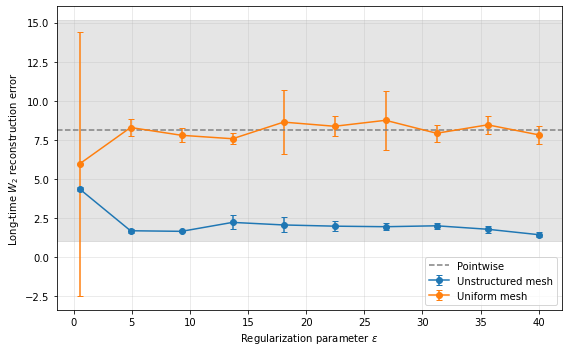

In [15]:
metric = 0
plt.figure(figsize=(8, 5))

for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds  = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
baseline_mean = baseline.mean()
baseline_std = baseline.std()

plt.axhline(baseline_mean, color='gray', linestyle='--', label='Pointwise')
plt.axhspan(
    baseline_mean - baseline_std,
    baseline_mean + baseline_std,
    color='gray',
    alpha=0.2
)

plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()

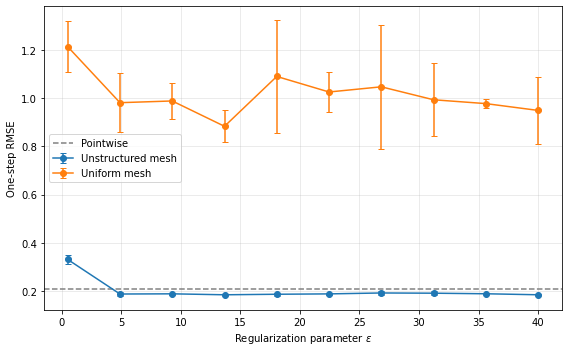

In [11]:
# NEW: Figure comparing three methods (0 = long-time W2, 1 = one-step RMSE)
metric = 1
plt.figure(figsize=(8, 5))
for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
plt.axhline(baseline.mean(), color='gray', linestyle='--', label='Pointwise')
plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()

In [ ]:
results

In [ ]:
errors

In [ ]:
metric = 1
plt.figure(figsize=(8, 5))
for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
plt.axhline(baseline.mean(), color='gray', linestyle='--', label='Pointwise')
plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'RMSE reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()